# Analysis code for the results reported in the manuscript

This notebook computes all the resultss reported in the Results section:  

| Section | Analysis |
|---|---|
| 1 | Data overview|
| 2 | Tables 2–4: background characteristics |
| 3 | The fifteen background features used in the models |
| 4 | Survey items by research question with complete texts and mapping  |
| 5 | Tables 5 and 7; Figures 1 and 2 |
| 6 | Table 6 |
| 7 | Table 8; Figure 3 |


In [18]:
import re, sys
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
from scipy import stats
import statsmodels, statsmodels.api as sm
import warnings; warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 300); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

HERE = Path.cwd()
DATA = HERE / "data" / "AI4S_survey_synthetic_n200_11_23_2026.csv"   # <- change this to run on another file
OUT = HERE / "outputs"; OUT.mkdir(exist_ok=True)

ALPHA = 0.05            # features are reported when the feature-level test has p <= ALPHA
MIN_N = 10              # response levels with <= MIN_N respondents are merged into "Other"; an "Other" with <= MIN_N is left out of the models
COUNTRY_MIN_N = 11      # countries with fewer respondents than this are grouped as "Other" in Table 2

## 1. Data overview

In [19]:
raw = pd.read_csv(DATA, header=None, dtype=str, keep_default_na=False, encoding="utf-8-sig")
codes, labels = raw.iloc[0].tolist(), raw.iloc[1].tolist(); LABEL = dict(zip(codes, labels))
allrec = raw.iloc[3:].copy(); allrec.columns = codes; allrec = allrec.reset_index(drop=True)

preview = allrec["DistributionChannel"].eq("preview") | allrec["Status"].str.contains("Preview", na=False)
df = allrec[~preview]
BG = [c for c in codes if c.startswith("BG_") or c == "Q65"]            # background block (free-text fields included)
answered_bg = (df[BG] != "").any(axis=1)
resp = df[answered_bg].copy().reset_index(drop=True); N = len(resp)

def s(col): return resp[col].astype(str).str.strip()
def likert(col):
    # responses look like "6 - Agree": keep the leading digit (1-7)
    v = pd.to_numeric(s(col).str.split(" ").str[0], errors="coerce"); return v.where(v.between(1, 7))

# item-level n across the closed survey items (26 background items and the 1-7 rating items)
BG_ITEMS = [f"BG_Q{i}" for i in range(1, 26)] + ["Q65"]
RATING_ITEMS = [c for c in codes if c not in BG and resp[c].str.match(r"^[1-7] - ").any()]
item_n = pd.Series({c: int((resp[c] != "").sum()) for c in BG_ITEMS + RATING_ITEMS})
flow = pd.DataFrame({"count": {"Records in the export": len(allrec), "Previews by the research team": int(preview.sum()),
        "Opened the consent page only (no item answered)": int((~answered_bg).sum()), "Analytic sample (answered at least one item)": N,
        "Smallest item n (all closed items)": int(item_n.min()), "Largest item n (all closed items)": int(item_n.max()),
        "Smallest n among the items analysed in this paper": int(min((resp[c] != "").sum() for c in ["P3_2", "Q95", "P3_4", "P1_2", "P3_6", "Q77", "Q102", "P3_8", "Q101", "P1_3", "P4_1", "P3_10", "Q80", "Q79", "P3_11"])),
        "Reached the end of the survey (Qualtrics 'Finished')": int(resp["Finished"].eq("True").sum())}})
flow.to_csv(OUT / "sample_flow.csv"); flow

,count
Records in the export,200
Previews by the research team,0
Opened the consent page only (no item answered),75
Analytic sample (answered at least one item),125
Smallest item n (all closed items),98
Largest item n (all closed items),125
Smallest n among the items analysed in this paper,98
Reached the end of the survey (Qualtrics 'Finished'),98


## 2. Background characteristics (Tables 2–4)

Percentages are of the respondents who answered each item. Recoding done here:
- **Position:** respondents who chose "other" and described themselves as doctoral or master's students are shown as such.
- **Country:** countries with fewer than 11 respondents are grouped as "Other".
- **First language:** a select-all item with a free-text field; answers are mapped to language groups, so one respondent can count in several.
- **Frequency of use:** "Rarely" and "Do not use AI" are shown together. Respondents who chose "Do not use AI" on the first-use item are left out of that item.

In [20]:
STUDENT_RE = re.compile(r"(ph\.?\s?d|doctor|master|\bm[12]\b|graduate|postgraduate|student)", re.I); UNDERGRAD_RE = re.compile(r"undergrad", re.I)
def is_grad_student(text): return bool(STUDENT_RE.search(text)) and not UNDERGRAD_RE.search(text)

def position(row):
    p, t = row["BG_Q3"].strip(), row["BG_Q3_7_TEXT"].strip()
    if p == "": return ""
    if p.startswith("Others"): return "Doctoral / Master's student" if is_grad_student(t) else "Other"
    return p.replace("Faculty- ", "Faculty — ")
resp["position_rc"] = resp.apply(position, axis=1)
resp["country_rc"] = s("BG_Q7").replace({"United States of America": "United States"})

LANG_MAP = [("Japanese", r"japan|日本"), ("Chinese", r"chin|mandarin|manderin|cantonese|taiwanese"), ("French", r"fren"), ("Spanish", r"spani"), ("German", r"german"), ("Italian", r"ital")]
def languages(row):
    out = set()
    if "English" in row["Q65"]: out.add("English")
    t = row["Q65_2_TEXT"].strip()
    if t:
        matched = False
        for name, pat in LANG_MAP:
            if re.search(pat, t, re.I): out.add(name); matched = True
        if re.search(r"english", t, re.I): out.add("English"); matched = True
        for part in [p for p in re.split(r"[,/;&]| and ", t) if p.strip()]:
            if not any(re.search(pat, part, re.I) for _, pat in LANG_MAP) and not re.search(r"english", part, re.I): out.add("Other")
        if not matched: out.add("Other")
    return out
resp["langs"] = resp.apply(languages, axis=1)

TOOL = {"GitHub Copilot or similar coding assistant": "GitHub Copilot or similar", "A domain-specific or in-house AI tool": "Domain-specific / in-house tool", "Others- please specify:": "Other"}
TASK = {"Literature search or summarising papers": "Literature search / summarising papers", "Learning a new field of knowledge": "Learning a new field",
        "Brainstorming or refining research ideas": "Brainstorming / refining ideas", "Drafting grant proposals or manuscripts": "Drafting grants or manuscripts",
        "Marking or giving feedback on student work": "Marking / feedback on student work", "Others- please specify:": "Other"}
def multi(col, m): return s(col).apply(lambda v: [m.get(p.strip(), p.strip()) for p in v.split(",") if p.strip()] if v else [])
PAYS = {"My institution or research funding pays for the AI tools": "Institution / research funding", "I pay for the AI services myself": "Pay myself",
        "it’s a mix of personal spending and institutional support": "Mix of personal and institutional", "It is a mix of personal spending and institutional support": "Mix of personal and institutional"}

def single(title, series, order=None):
    v = series[series != ""]; n = len(v); vc = v.value_counts()
    if order is None: order = [k for k in vc.index if k != "Other"] + (["Other"] if "Other" in vc.index else [])
    return [(title, n, lab, int(vc.get(lab, 0)), round(100 * vc.get(lab, 0) / n, 1)) for lab in order if vc.get(lab, 0) > 0]
def select_all(title, lists, order=None, sort=False):
    L = lists[lists.apply(len) > 0]; n = len(L); cnt = pd.Series([x for xs in L for x in set(xs)]).value_counts()
    if order is None: order = [k for k in cnt.index if k != "Other"] + (["Other"] if "Other" in cnt.index else [])
    rows = [(title + " (select all that apply)", n, lab, int(cnt.get(lab, 0)), round(100 * cnt.get(lab, 0) / n, 1)) for lab in order if cnt.get(lab, 0) > 0]
    return sorted(rows, key=lambda r: (r[2] == "Other", -r[3])) if sort else rows
def country(title, series):
    v = series[series != ""]; n = len(v); vc = v.value_counts(); big, small = vc[vc >= COUNTRY_MIN_N], vc[vc < COUNTRY_MIN_N]
    return [(title, n, k, int(c), round(100 * c / n, 1)) for k, c in big.items()] + [(title, n, f"Other ({len(small)} countries)", int(small.sum()), round(100 * small.sum() / n, 1))]
def table(blocks): return pd.DataFrame([r for b in blocks for r in b], columns=["Characteristic", "n answered", "Category", "n", "%"])

table2 = table([
    single("Age band", s("BG_Q5"), ["Under 35", "35-44", "45-54", "55-64", "65 or over"]),
    single("Gender", s("BG_Q6"), ["Man", "Woman", "Non-binary", "Prefer to self-describe:", "Prefer not to say"]),
    country("Country of employment", resp["country_rc"]),
    select_all("First (native) language", resp["langs"], ["Japanese", "English", "Chinese", "French", "Spanish", "Italian", "German", "Other"])])
table2.to_csv(OUT / "table2_demographics.csv", index=False); table2

,Characteristic,n answered,Category,n,%
0,Age band,125,Under 35,60,48.0
1,Age band,125,35-44,20,16.0
2,Age band,125,45-54,16,12.8
3,Age band,125,55-64,12,9.6
4,Age band,125,65 or over,17,13.6
5,Gender,125,Man,106,84.8
6,Gender,125,Woman,19,15.2
7,Country of employment,125,Japan,67,53.6
8,Country of employment,125,United Kingdom,32,25.6
9,Country of employment,125,United States,22,17.6


In [21]:
table3 = table([
    single("Holds a PhD in physics or a closely related field", s("BG_Q1"), ["Yes", "No"]),
    single("Employed full-time in a research or faculty role", s("BG_Q2"), ["Yes", "No"]),
    single("Current position", resp["position_rc"], ["Postdoc / research fellow", "Doctoral / Master's student", "Faculty — associate professor", "Faculty — full professor",
                                                      "Faculty — assistant professor", "Staff scientist", "Senior staff scientist", "Other"]),
    single("Years since completing PhD", s("BG_Q4").replace({"Still in training or does not have a PhD": "Still in training / no PhD"}), ["Still in training / no PhD", "0-2", "3-5", "6-10", "11-20", "More than 20"]),
    single("Institution type", s("BG_Q8").replace({"University / College": "University / college", "Others- please specify:": "Other"}), ["University / college", "National laboratory", "Independent research institute", "Other"]),
    single("Main physics subfield", s("BG_Q9").replace({"Others- please specify:": "Other"})),
    single("Primary mode of work", s("BG_Q10"), ["Experimental", "Theory", "Computational", "Mixed / no single primary mode"]),
    single("Doctoral students supervised", s("BG_Q11").replace({"None": "None (0)"}), ["None (0)", "1-2", "3-5", "6 or more"]),
    single("Teaches or assesses formal courses", s("BG_Q12"), ["Regularly", "Occasionally", "No"]),
    single("Typical research collaboration size", s("BG_Q13"), ["Solo", "Small group (fewer than 5 people)", "Medium (5-30 people)", "Large (more than 30 people)"])])
table3.to_csv(OUT / "table3_research_status.csv", index=False); table3

,Characteristic,n answered,Category,n,%
0,Holds a PhD in physics or a closely related field,125,Yes,94,75.2
1,Holds a PhD in physics or a closely related field,125,No,31,24.8
2,Employed full-time in a research or faculty role,125,Yes,106,84.8
3,Employed full-time in a research or faculty role,125,No,19,15.2
4,Current position,125,Postdoc / research fellow,26,20.8
5,Current position,125,Doctoral / Master's student,16,12.8
6,Current position,125,Faculty — associate professor,14,11.2
7,Current position,125,Faculty — full professor,21,16.8
8,Current position,125,Faculty — assistant professor,1,0.8
9,Current position,125,Staff scientist,1,0.8


In [22]:
freq_rc = s("BG_Q15").replace({"Rarely": "Rarely or do not use AI", "Do not use AI": "Rarely or do not use AI"})
first_rc = s("BG_Q16").replace({"Do not use AI": ""})
table4 = table([
    single("Has used generative-AI tools for work", s("BG_Q14"), ["Yes", "No"]),
    single("Frequency of generative-AI use", freq_rc, ["Daily", "Several times a week", "About weekly", "About monthly", "Rarely or do not use AI"]),
    single("When first started using generative AI", first_rc, ["Within the past 6 months", "6-12 months ago", "1-2 years ago", "More than 2 years ago"]),
    select_all("Tools used", multi("BG_Q17", TOOL), ["ChatGPT (OpenAI)", "Claude (Anthropic)", "Gemini (Google)", "GitHub Copilot or similar", "Domain-specific / in-house tool", "Other"]),
    select_all("Tasks AI is used for", multi("BG_Q18", TASK), sort=True),
    single("Self-rated generative-AI proficiency", s("BG_Q19").str.split(" - ").str[0], ["Expert", "Advanced", "Intermediate", "Beginner", "No experience"]),
    single("Used machine learning or data science methods before generative AI", s("BG_Q20"), ["Yes", "No"]),
    single("Who pays for the AI tools", s("BG_Q21").str.rstrip(".").replace(PAYS), ["Institution / research funding", "Pay myself", "Mix of personal and institutional"]),
    single("Students / junior researchers use generative AI", s("BG_Q22"), ["Most of them", "Some of them", "None of them", "I do not know"]),
    single("Institution has a generative-AI policy", s("BG_Q23"), ["Yes", "No", "I do not know"]),
    single("Asks students to disclose AI use", s("BG_Q24").str.replace("–", "-"), ["Always", "Sometimes", "Never", "Not applicable - I do not assess student work"]),
    single("Asks students to restrict AI use", s("BG_Q25").str.replace("–", "-"), ["Always", "Sometimes", "Never", "Not applicable - I do not mentor student work"])])
table4.to_csv(OUT / "table4_ai_use.csv", index=False); table4

,Characteristic,n answered,Category,n,%
0,Has used generative-AI tools for work,122,Yes,112,91.8
1,Has used generative-AI tools for work,122,No,10,8.2
2,Frequency of generative-AI use,122,Daily,79,64.8
3,Frequency of generative-AI use,122,Several times a week,26,21.3
4,Frequency of generative-AI use,122,About weekly,3,2.5
5,Frequency of generative-AI use,122,Rarely or do not use AI,14,11.5
6,When first started using generative AI,122,Within the past 6 months,27,22.1
7,When first started using generative AI,122,6-12 months ago,41,33.6
8,When first started using generative AI,122,1-2 years ago,36,29.5
9,When first started using generative AI,122,More than 2 years ago,18,14.8


## 3. Background features used in the models

Fifteen features. Twelve use the original response options. Three are derived here:

- **Mentor status**: from current position. Faculty and staff scientists of any rank are mentors; postdoctoral researchers and graduate students are mentees. Other positions are not classified.
- **Region of employment**: country of employment grouped into Asia, Europe, North America and other.
- **AI usage status**: non-users answered "No" to having used generative AI for work. For users, frequency of use, time since first use and self-rated proficiency are standardized (z-scores) and averaged; users are split at the 33.3rd and 66.7th percentiles into low, medium and high.

A level chosen by 10 or fewer respondents is merged into "Other"; an "Other" that still has 10 or fewer is left out of the models. The first level listed for each feature is the reference level.

In [23]:
# ---- Mentor status ----
def mentor_status(row):
    p, t = row["BG_Q3"].strip(), row["BG_Q3_7_TEXT"].strip()
    if p.startswith("Faculty") or p in ("Staff scientist", "Senior staff scientist"): return "Mentor"
    if p == "Postdoc / research fellow" or (p.startswith("Others") and is_grad_student(t)): return "Mentee"
    return None
mentor = resp.apply(mentor_status, axis=1)

# ---- Region of employment ----
REGION = {"Asia": ["Japan", "Taiwan", "China", "South Korea", "India", "Philippines"],
          "Europe": ["United Kingdom", "France", "Italy", "Spain", "Germany", "Switzerland", "Poland", "Ireland", "Denmark", "Slovenia", "Belgium", "Norway"],
          "North America": ["United States of America", "Canada"]}
def region_of(c):
    if not c: return None
    return next((r for r, members in REGION.items() if c in members), "Other")
region = s("BG_Q7").map(region_of)

# ---- AI usage status ----
FREQ  = {"Do not use AI": 0, "Rarely": 1, "About monthly": 2, "About weekly": 3, "Several times a week": 4, "Daily": 5}
FIRST = {"Do not use AI": 0, "Within the past 6 months": 1, "6-12 months ago": 2, "1-2 years ago": 3, "More than 2 years ago": 4}
PROF  = {"No experience": 0, "Beginner": 1, "Intermediate": 2, "Advanced": 3, "Expert": 4}
used = s("BG_Q14")
parts = pd.concat([s("BG_Q15").map(FREQ), s("BG_Q16").map(FIRST), s("BG_Q19").str.split(" - ").str[0].map(PROF)], axis=1)
scored = used.eq("Yes") & parts.notna().all(axis=1)
Z = parts[scored].astype(float); Z = (Z - Z.mean()) / Z.std(ddof=1); composite = Z.mean(axis=1)
lo, hi = np.percentile(composite, [100 / 3, 200 / 3])
ai_status = pd.Series(None, index=resp.index, dtype="object")
ai_status[used.eq("No")] = "Non-use"
ai_status[composite[composite <= lo].index] = "Low"
ai_status[composite[(composite > lo) & (composite <= hi)].index] = "Medium"
ai_status[composite[composite > hi].index] = "High"

derived = pd.concat([mentor.value_counts().reindex(["Mentor", "Mentee"]).rename("Mentor status"),
                     region.value_counts().reindex(["Asia", "Europe", "North America", "Other"]).rename("Region of employment"),
                     ai_status.value_counts().reindex(["Non-use", "Low", "Medium", "High"]).rename("AI usage status")], axis=1).T.stack().astype(int).rename("n").to_frame()
derived.to_csv(OUT / "derived_features.csv"); derived

n
Mentor status        Mentor         47
                     Mentee         42
Region of employment Asia           67
                     Europe         32
                     North America  22
                     Other           4
AI usage status      Non-use        10
                     Low            39
                     Medium         42
                     High           31

In [24]:
def opt(col, mapping=None):
    x = s(col).replace("", None)
    return x.map(lambda v: mapping.get(v, v) if v is not None else None) if mapping else x
OTH = {"Others- please specify:": "Other"}
NA_ = {"Not applicable - I do not assess student work": "Not applicable", "Not applicable - I do not mentor student work": "Not applicable",
       "Not applicable – I do not assess student work": "Not applicable", "Not applicable – I do not mentor student work": "Not applicable"}

# (feature, values, levels in order [first = reference], label of an existing "other" option)
SPECS = [
 ("Gender",                opt("BG_Q6"), ["Man", "Woman", "Non-binary", "Prefer not to say"], None),
 ("Mentor status",         mentor, ["Mentor", "Mentee"], None),
 ("Age band",              opt("BG_Q5", {"35-44": "35–44", "45-54": "45–54", "55-64": "55–64"}), ["Under 35", "35–44", "45–54", "55–64", "65 or over"], None),
 ("Years since PhD",       opt("BG_Q4", {"Still in training or does not have a PhD": "In training / no PhD", "0-2": "0–2", "3-5": "3–5", "6-10": "6–10", "11-20": "11–20"}),
                           ["In training / no PhD", "0–2", "3–5", "6–10", "11–20", "More than 20"], None),
 ("Institution type",      opt("BG_Q8", {"University / College": "University / college", **OTH}), ["University / college", "National laboratory", "Independent research institute", "Other"], "Other"),
 ("Research mode",         opt("BG_Q10"), ["Theory", "Experimental", "Computational", "Mixed / no single primary mode"], None),
 ("Subfield",              opt("BG_Q9", {"Particle / high-energy physics": "Particle / high-energy", **OTH}),
                           ["Particle / high-energy", "Cosmology", "Condensed matter / materials", "Astrophysics", "Biophysics", "Nuclear physics", "Atomic, molecular and optical", "Other"], "Other"),
 ("Collaboration size",    opt("BG_Q13", {"Small group (fewer than 5 people)": "Small (< 5)", "Medium (5-30 people)": "Medium (5–30)", "Large (more than 30 people)": "Large (> 30)"}),
                           ["Small (< 5)", "Solo", "Medium (5–30)", "Large (> 30)"], None),
 ("Region of employment",  region, ["Asia", "Europe", "North America", "Other"], "Other"),
 ("AI usage status",       ai_status, ["Low", "Medium", "High", "Non-use"], None),
 ("Prior ML use",          opt("BG_Q20"), ["No", "Yes"], None),
 ("Students use AI",       opt("BG_Q22"), ["Most of them", "Some of them", "I do not know", "None of them"], None),
 ("Institution AI policy", opt("BG_Q23"), ["Yes", "No", "I do not know"], None),
 ("Asks to disclose AI",   opt("BG_Q24", NA_), ["Never", "Sometimes", "Always", "Not applicable"], None),
 ("Asks to restrict AI",   opt("BG_Q25", NA_), ["Never", "Sometimes", "Always", "Not applicable"], None)]

FEATURES, rows = {}, []          # FEATURES[name] = (values after the small-group rule, levels used in the models)
for name, x, order, other in SPECS:
    x = x.where(x.isin(order)); vc = x.value_counts().reindex(order).fillna(0).astype(int)
    small = [l for l in order if vc[l] <= MIN_N and l != other]
    xm = x.replace({l: "Other" for l in small}); n_other = int((xm == "Other").sum())
    levels = [l for l in order if l not in small and l != other] + (["Other"] if (small or other) and n_other > MIN_N else [])
    FEATURES[name] = (xm, levels)
    for l in order:
        if l in small: how = "merged into Other" if n_other > MIN_N else "left out of the models"
        elif l == other: how = "kept" if n_other > MIN_N else "left out of the models"
        else: how = "reference level" if l == levels[0] else "kept"
        rows.append((name, int(vc.sum()), l, int(vc[l]), how))
feature_table = pd.DataFrame(rows, columns=["Feature", "valid n", "Level", "n", "Handling in the models"])
feature_table.to_csv(OUT / "feature_table.csv", index=False); feature_table

,Feature,valid n,Level,n,Handling in the models
0,Gender,125,Man,106,reference level
1,Gender,125,Woman,19,kept
2,Gender,125,Non-binary,0,left out of the models
3,Gender,125,Prefer not to say,0,left out of the models
4,Mentor status,89,Mentor,47,reference level
5,Mentor status,89,Mentee,42,kept
6,Age band,125,Under 35,60,reference level
7,Age band,125,35–44,20,kept
8,Age band,125,45–54,16,kept
9,Age band,125,55–64,12,kept


## 4. Survey items by research question (Table 1)

In [25]:
# (label, export code, construct, item wording); Q1-Q11 are the labels used in Table 7
RQ1 = [("", "P3_2", "Irreplaceable human core of mentorship", "Good research supervision depends on expression, tone, and empathy that AI cannot supply."),
       ("", "Q95",  "Irreplaceable human core of mentorship", "Human advisers prepare students for their careers and their lives, not only for knowledge and technical skills. This cannot be replaced by AI."),
       ("", "P3_4", "Displacement of the human core", "Young researchers will feel discouraged from asking their mentors questions because AI has a better answer.")]
F1, F2, F3 = "Function 1: Problem finding and research formulation", "Function 2: Critical evaluation and oversight of AI", "Function 3: Building skill competence before AI"
RQ2 = [("", "P1_2", "Anchor question", "I believe the role of physicists will change significantly due to the advancement of AI."),
       ("Q1", "P3_6", F1, "With the emergence of AI, what makes a good physicist is shifting from being able to calculate towards asking the right questions."),
       ("Q2", "Q77",  F1, "Even with AI, the scientist’s defining work remains asking the right questions and connecting ideas."),
       ("Q3", "Q102", F1, "Deciding which scientific questions are worth pursuing should remain a researcher’s responsibility."),
       ("Q4", "P3_8", F2, "Students should learn from human advisors how to evaluate the work of AI, including where it fails."),
       ("Q5", "Q101", F2, "As AI increases the speed at which research results can be produced, science should prioritize verification."),
       ("Q6", "P1_3", F2, "As AI advances, the most important role of physicists will be to determine how to direct and use AI."),
       ("Q7", "P4_1", F2, "When using AI-generation, human researchers should bear the ultimate responsibility for the correctness of the results."),
       ("Q8", "P3_10", F3, "Students should be prevented from using AI until they have learned the fundamentals."),
       ("Q9", "Q80",  F3, "You have to be able to do the mathematics yourself, or you are not really a scientist."),
       ("Q10", "Q79", F3, "The slow struggle of doing the work yourself is how you truly learn, and skipping this through AI is detrimental."),
       ("Q11", "P3_11", F3, "Students with strong prior knowledge and skills benefit more from using AI than those without strong preparation for the field.")]
SPLIT = ["P1_3", "Q80", "P3_10"]          # the three RQ2 items on which views were split
WORDING = {c: w for _, c, _, w in RQ1 + RQ2}
items = pd.DataFrame([("RQ1",) + r for r in RQ1] + [("RQ2",) + r for r in RQ2], columns=["RQ", "Label", "Export code", "Construct", "Survey item"])
items["Question text in the data file"] = items["Export code"].map(lambda c: LABEL[c].split(" - ")[-1][:70])
items.to_csv(OUT / "table1_items.csv", index=False); items

,RQ,Label,Export code,Construct,Survey item,Question text in the data file
0,RQ1,,P3_2,Irreplaceable human core of mentorship,"Good research supervision depends on expression, tone, and empathy that AI c...","Good research supervision depends on expression, tone, and empathy tha"
1,RQ1,,Q95,Irreplaceable human core of mentorship,"Human advisers prepare students for their careers and their lives, not only ...","Human advisers prepare students for their careers and their lives, not"
2,RQ1,,P3_4,Displacement of the human core,Young researchers will feel discouraged from asking their mentors questions ...,Young researchers will feel discouraged from asking their mentors ques
3,RQ2,,P1_2,Anchor question,I believe the role of physicists will change significantly due to the advanc...,I believe the role of physicists will change significantly due to the
4,RQ2,Q1,P3_6,Function 1: Problem finding and research formulation,"With the emergence of AI, what makes a good physicist is shifting from being...","With the emergence of AI, what makes a good physicist is shifting from"
5,RQ2,Q2,Q77,Function 1: Problem finding and research formulation,"Even with AI, the scientist’s defining work remains asking the right questio...","Even with AI, the scientist's defining work remains asking the right q"
6,RQ2,Q3,Q102,Function 1: Problem finding and research formulation,Deciding which scientific questions are worth pursuing should remain a resea...,Deciding which scientific questions are worth pursuing should remain a
7,RQ2,Q4,P3_8,Function 2: Critical evaluation and oversight of AI,"Students should learn from human advisors how to evaluate the work of AI, in...",Students should learn from human advisors how to evaluate the work of
8,RQ2,Q5,Q101,Function 2: Critical evaluation and oversight of AI,"As AI increases the speed at which research results can be produced, science...","As AI increases the speed at which research results can be produced, s"
9,RQ2,Q6,P1_3,Function 2: Critical evaluation and oversight of AI,"As AI advances, the most important role of physicists will be to determine h...","I believe that, as AI advances, the most important role of physicists"


## 5. Response distributions (Tables 5 and 7; Figures 1 and 2)


In [26]:
def distribution(item_list):
    rows = []
    for lab, c, construct, wording in item_list:
        v = likert(c).dropna(); n = len(v); r = {"Construct": construct, "Label": lab, "Survey item": wording, "n": n}
        for k in range(1, 8): r[f"n{k}"] = int((v == k).sum()); r[f"%{k}"] = round(100 * (v == k).sum() / n, 1)
        r.update({"Mean": round(v.mean(), 2), "SD": round(v.std(ddof=1), 2), "% disagree (1-3)": round(100 * (v <= 3).sum() / n, 1),
                  "% neutral (4)": round(100 * (v == 4).sum() / n, 1), "% agree (5-7)": round(100 * (v >= 5).sum() / n, 1)}); rows.append(r)
    return pd.DataFrame(rows)
table5 = distribution(RQ1); table5.to_csv(OUT / "table5_rq1_distributions.csv", index=False); table5

,Construct,Label,Survey item,n,n1,%1,n2,%2,n3,%3,...,%5,n6,%6,n7,%7,Mean,SD,% disagree (1-3),% neutral (4),% agree (5-7)
0,Irreplaceable human core of mentorship,,"Good research supervision depends on expression, tone, and empathy that AI c...",99,6,6.1,10,10.1,5,5.1,...,20.2,38,38.4,12,12.1,4.90,1.75,21.2,8.1,70.7
1,Irreplaceable human core of mentorship,,"Human advisers prepare students for their careers and their lives, not only ...",105,2,1.9,0,0.0,11,10.5,...,9.5,27,25.7,46,43.8,5.76,1.50,12.4,8.6,79.0
2,Displacement of the human core,,Young researchers will feel discouraged from asking their mentors questions ...,105,11,10.5,44,41.9,8,7.6,...,12.4,15,14.3,0,0.0,3.18,1.66,60.0,13.3,26.7


In [27]:
table7 = distribution(RQ2); table7.to_csv(OUT / "table7_rq2_distributions.csv", index=False); table7

,Construct,Label,Survey item,n,n1,%1,n2,%2,n3,%3,...,%5,n6,%6,n7,%7,Mean,SD,% disagree (1-3),% neutral (4),% agree (5-7)
0,Anchor question,,I believe the role of physicists will change significantly due to the advanc...,102,0,0.0,14,13.7,4,3.9,...,14.7,40,39.2,25,24.5,5.35,1.64,17.6,3.9,78.4
1,Function 1: Problem finding and research formulation,Q1,"With the emergence of AI, what makes a good physicist is shifting from being...",99,0,0.0,3,3.0,9,9.1,...,34.3,24,24.2,16,16.2,5.16,1.28,12.1,13.1,74.7
2,Function 1: Problem finding and research formulation,Q2,"Even with AI, the scientist’s defining work remains asking the right questio...",98,0,0.0,3,3.1,0,0.0,...,21.4,34,34.7,40,40.8,6.07,1.06,3.1,0.0,96.9
3,Function 1: Problem finding and research formulation,Q3,Deciding which scientific questions are worth pursuing should remain a resea...,102,0,0.0,0,0.0,3,2.9,...,14.7,37,36.3,47,46.1,6.23,0.91,2.9,0.0,97.1
4,Function 2: Critical evaluation and oversight of AI,Q4,"Students should learn from human advisors how to evaluate the work of AI, in...",99,0,0.0,0,0.0,8,8.1,...,9.1,48,48.5,28,28.3,5.83,1.15,8.1,6.1,85.9
5,Function 2: Critical evaluation and oversight of AI,Q5,"As AI increases the speed at which research results can be produced, science...",106,0,0.0,7,6.6,3,2.8,...,36.8,15,14.2,37,34.9,5.54,1.42,9.4,4.7,85.8
6,Function 2: Critical evaluation and oversight of AI,Q6,"As AI advances, the most important role of physicists will be to determine h...",102,3,2.9,23,22.5,9,8.8,...,23.5,0,0.0,18,17.6,4.14,1.76,34.3,24.5,41.2
7,Function 2: Critical evaluation and oversight of AI,Q7,"When using AI-generation, human researchers should bear the ultimate respons...",106,4,3.8,3,2.8,0,0.0,...,0.0,32,30.2,67,63.2,6.33,1.39,6.6,0.0,93.4
8,Function 3: Building skill competence before AI,Q8,Students should be prevented from using AI until they have learned the funda...,105,7,6.7,19,18.1,10,9.5,...,19.0,18,17.1,18,17.1,4.39,1.93,34.3,12.4,53.3
9,Function 3: Building skill competence before AI,Q9,"You have to be able to do the mathematics yourself, or you are not really a ...",98,9,9.2,19,19.4,13,13.3,...,26.5,15,15.3,13,13.3,4.17,1.95,41.8,3.1,55.1


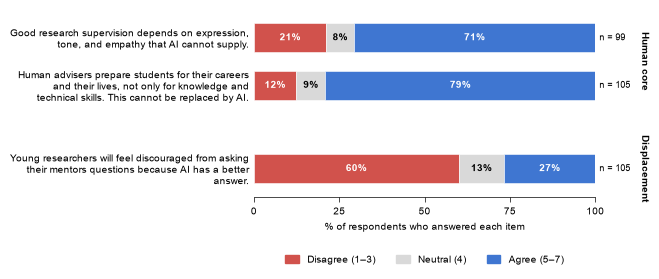

In [28]:
# ---- figure settings: 170 mm wide, 300 dpi ----
matplotlib.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"], "pdf.fonttype": 42, "font.size": 7.5, "axes.linewidth": 0.5, "xtick.major.width": 0.5})
MM = 1 / 25.4; W = 170 * MM; RED, GREY, BLUE = "#D1524C", "#D9D9D9", "#3F76D1"
KEY = [Patch(color=RED, label="Disagree (1–3)"), Patch(color=GREY, label="Neutral (4)"), Patch(color=BLUE, label="Agree (5–7)")]
def save(fig, name):
    for ext in ("png", "pdf"): fig.savefig(OUT / f"{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)
def shares(v):
    v = v.dropna(); n = len(v); return dict(n=n, dis=100 * (v <= 3).sum() / n, neu=100 * (v == 4).sum() / n, agr=100 * (v >= 5).sum() / n)

def stacked(groups, name, height_mm, label_frac):
    # groups: [(group label, [(bar label, export code), ...]), ...]
    fig, ax = plt.subplots(figsize=(W, height_mm * MM)); y = 0; yt, yl = [], []
    for gname, bars in groups:
        top = y
        for lab, c in bars:
            d = shares(likert(c)); left = 0
            for k, col, tc in (("dis", RED, "white"), ("neu", GREY, "black"), ("agr", BLUE, "white")):
                ax.barh(y, d[k], left=left, color=col, height=0.62, edgecolor="white", linewidth=0.4)
                if d[k] >= 5: ax.text(left + d[k] / 2, y, f"{d[k]:.0f}%", ha="center", va="center", fontsize=7, fontweight="bold", color=tc)
                left += d[k]
            ax.text(101.2, y, f"n = {d['n']}", va="center", fontsize=6.5); yt.append(y); yl.append(lab); y -= 1
        ax.text(114.5, (top + y + 1) / 2, gname, rotation=270, va="center", ha="center", fontsize=7, fontweight="bold", clip_on=False); y -= 0.75
    ax.set_yticks(yt); ax.set_yticklabels(yl, fontsize=7.5); ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 100); ax.set_ylim(y + 1.15, 0.6); ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xlabel("% of respondents who answered each item", fontsize=7.5)
    for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
    ax.legend(handles=KEY, loc="upper center", bbox_to_anchor=(0.5, -0.55 / len(yt) - 0.075), ncol=3, frameon=False, fontsize=7.5, handlelength=1.3)
    fig.subplots_adjust(left=label_frac, right=0.87); save(fig, name); plt.show()

stacked([("Human core", [("Good research supervision depends on expression,\ntone, and empathy that AI cannot supply.", "P3_2"),
                         ("Human advisers prepare students for their careers\nand their lives, not only for knowledge and\ntechnical skills. This cannot be replaced by AI.", "Q95")]),
         ("Displacement", [("Young researchers will feel discouraged from asking\ntheir mentors questions because AI has a better\nanswer.", "P3_4")])], "Figure1", 62, 0.36)

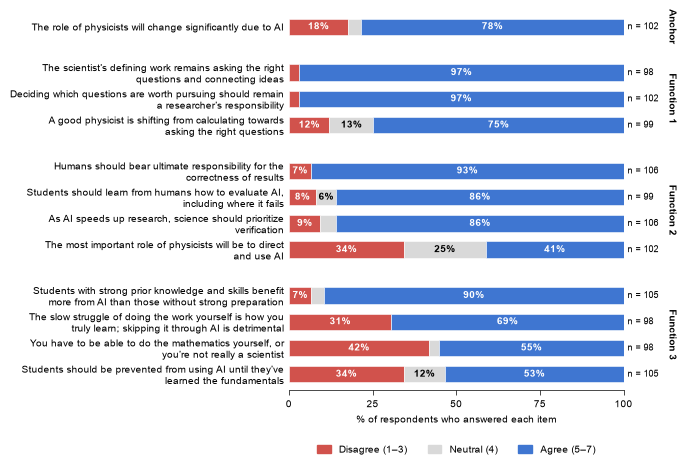

In [29]:
# Figure 2
stacked([("Anchor", [("The role of physicists will change significantly due to AI", "P1_2")]),
         ("Function 1", [("The scientist’s defining work remains asking the right\nquestions and connecting ideas", "Q77"),
                         ("Deciding which questions are worth pursuing should remain\na researcher’s responsibility", "Q102"),
                         ("A good physicist is shifting from calculating towards\nasking the right questions", "P3_6")]),
         ("Function 2", [("Humans should bear ultimate responsibility for the\ncorrectness of results", "P4_1"),
                         ("Students should learn from humans how to evaluate AI,\nincluding where it fails", "P3_8"),
                         ("As AI speeds up research, science should prioritize\nverification", "Q101"),
                         ("The most important role of physicists will be to direct\nand use AI", "P1_3")]),
         ("Function 3", [("Students with strong prior knowledge and skills benefit\nmore from AI than those without strong preparation", "P3_11"),
                         ("The slow struggle of doing the work yourself is how you\ntruly learn; skipping it through AI is detrimental", "Q79"),
                         ("You have to be able to do the mathematics yourself, or\nyou’re not really a scientist", "Q80"),
                         ("Students should be prevented from using AI until they’ve\nlearned the fundamentals", "P3_10")])], "Figure2", 125, 0.37)

## 6. RQ1 items: univariate OLS regressions (Table 6)

In [30]:
def dummies(x, levels):
    X = pd.get_dummies(pd.Categorical(x, categories=levels), drop_first=True).astype(float); X.columns = levels[1:]; X.index = x.index; return X

def ols_by_feature(code_):
    y = likert(code_); levels_out, tests = [], []
    for name, (x, levels) in FEATURES.items():
        d = pd.DataFrame({"y": y, "x": x}).dropna(); d = d[d["x"].isin(levels)]
        fit = sm.OLS(d["y"], sm.add_constant(dummies(d["x"], levels))).fit(); ci = fit.conf_int(); g = d.groupby("x")["y"].agg(["count", "mean"])
        for l in levels:
            ref = l == levels[0]
            levels_out.append({"Item": code_, "Feature": name, "Level": l + (" (ref)" if ref else ""), "n": int(g.loc[l, "count"]), "Mean": g.loc[l, "mean"],
                               "beta": np.nan if ref else fit.params[l], "SE": np.nan if ref else fit.bse[l], "CI low": np.nan if ref else ci.loc[l, 0], "CI high": np.nan if ref else ci.loc[l, 1], "p": np.nan if ref else fit.pvalues[l]})
        tests.append({"Item": code_, "Feature": name, "n": len(d), "F": fit.fvalue, "df1": int(fit.df_model), "df2": int(fit.df_resid), "F test p": fit.f_pvalue, "R2": fit.rsquared})
    return pd.DataFrame(levels_out), pd.DataFrame(tests)

res = [ols_by_feature(c) for _, c, _, _ in RQ1]
ols_levels = pd.concat([r[0] for r in res], ignore_index=True); ols_tests = pd.concat([r[1] for r in res], ignore_index=True)
ols_tests.round(4).to_csv(OUT / "rq1_ols_all_feature_tests.csv", index=False); ols_levels.round(4).to_csv(OUT / "rq1_ols_all_levels.csv", index=False)
ols_tests.round(3)

,Item,Feature,n,F,df1,df2,F test p,R2
0,P3_2,Gender,99,0.000,1,97,0.984,0.000
1,P3_2,Mentor status,70,0.381,1,68,0.539,0.006
2,P3_2,Age band,99,8.281,4,94,0.000,0.261
3,P3_2,Years since PhD,99,1.850,5,93,0.111,0.090
4,P3_2,Institution type,99,3.672,2,96,0.029,0.071
5,P3_2,Research mode,99,2.977,3,95,0.035,0.086
6,P3_2,Subfield,99,0.688,3,95,0.562,0.021
7,P3_2,Collaboration size,97,0.194,2,94,0.824,0.004
8,P3_2,Region of employment,95,2.706,2,92,0.072,0.056
9,P3_2,AI usage status,90,7.669,2,87,0.001,0.150


In [31]:
sig = ols_tests[ols_tests["F test p"] <= ALPHA][["Item", "Feature", "F test p"]]
table6 = ols_levels.merge(sig, on=["Item", "Feature"]); table6.insert(1, "Survey item", table6["Item"].map(WORDING)); table6.insert(2, "Item n", table6["Item"].map(lambda c: int(likert(c).notna().sum())))
table6.round(3).to_csv(OUT / "table6_rq1_ols_significant.csv", index=False); table6.drop(columns="Survey item").round({"Mean": 2, "beta": 2, "SE": 2, "CI low": 2, "CI high": 2, "p": 3, "F test p": 3})

,Item,Item n,Feature,Level,n,Mean,beta,SE,CI low,CI high,p,F test p
0,P3_2,99,Age band,Under 35 (ref),34,3.71,NaN,NaN,NaN,NaN,NaN,0.000
1,P3_2,99,Age band,35–44,20,5.85,2.14,0.43,1.29,3.00,0.000,0.000
2,P3_2,99,Age band,45–54,16,5.19,1.48,0.46,0.56,2.40,0.002,0.000
3,P3_2,99,Age band,55–64,12,5.58,1.88,0.51,0.86,2.90,0.000,0.000
4,P3_2,99,Age band,65 or over,17,5.41,1.71,0.46,0.80,2.61,0.000,0.000
5,P3_2,99,Institution type,University / college (ref),75,4.95,NaN,NaN,NaN,NaN,NaN,0.029
6,P3_2,99,Institution type,National laboratory,15,5.47,0.52,0.48,-0.43,1.47,0.282,0.029
7,P3_2,99,Institution type,Other,9,3.56,-1.39,0.60,-2.58,-0.20,0.023,0.029
8,P3_2,99,Research mode,Theory (ref),29,4.41,NaN,NaN,NaN,NaN,NaN,0.035
9,P3_2,99,Research mode,Experimental,36,5.47,1.06,0.42,0.22,1.90,0.014,0.035


## 7. Split RQ2 items: univariate logistic regressions (Table 8; Figure 3)

In [32]:
def logit_by_feature(code_):
    y7 = likert(code_); levels_out, tests = [], []
    for name, (x, levels) in FEATURES.items():
        d = pd.DataFrame({"y7": y7, "x": x}).dropna(); d = d[d["x"].isin(levels) & (d["y7"] != 4)]; d["y"] = (d["y7"] >= 5).astype(int)
        g = d.groupby("x")["y"].agg(["count", "sum"]).reindex(levels).fillna(0).astype(int)
        est = [l for l in levels if 0 < g.loc[l, "sum"] < g.loc[l, "count"]]; assert levels[0] in est
        de = d[d["x"].isin(est)]
        fit = sm.Logit(de["y"], sm.add_constant(dummies(de["x"], est))).fit(disp=0, maxiter=200); null = sm.Logit(de["y"], np.ones((len(de), 1))).fit(disp=0)
        ci = fit.conf_int()
        for l in levels:
            n_l, a_l = g.loc[l, "count"], g.loc[l, "sum"]; ref = l == levels[0]; ok = (l in est) and not ref
            levels_out.append({"Item": code_, "Feature": name, "Level": l + (" (ref)" if ref else ""), "n": int(n_l), "% agree": 100 * a_l / n_l if n_l else np.nan,
                               "beta": fit.params[l] if ok else np.nan, "SE": fit.bse[l] if ok else np.nan, "OR": 1.0 if ref else (np.exp(fit.params[l]) if ok else np.nan),
                               "CI low": np.exp(ci.loc[l, 0]) if ok else np.nan, "CI high": np.exp(ci.loc[l, 1]) if ok else np.nan, "p": fit.pvalues[l] if ok else np.nan,
                               "Note": "" if (ok or ref) else "not estimable"})
        tests.append({"Item": code_, "Feature": name, "n agree": int(de["y"].sum()), "n disagree": int((de["y"] == 0).sum()),
                      "LR chi2": 2 * (fit.llf - null.llf), "df": len(est) - 1, "LR test p": stats.chi2.sf(2 * (fit.llf - null.llf), len(est) - 1)})
    return pd.DataFrame(levels_out), pd.DataFrame(tests)

res = [logit_by_feature(c) for c in SPLIT]
logit_levels = pd.concat([r[0] for r in res], ignore_index=True); logit_tests = pd.concat([r[1] for r in res], ignore_index=True)
logit_tests.round(4).to_csv(OUT / "rq2_logit_all_feature_tests.csv", index=False); logit_levels.round(4).to_csv(OUT / "rq2_logit_all_levels.csv", index=False)
logit_tests.round(3)

,Item,Feature,n agree,n disagree,LR chi2,df,LR test p
0,P1_3,Gender,42,35,0.417,1,0.518
1,P1_3,Mentor status,27,27,0.297,1,0.586
2,P1_3,Age band,42,35,2.209,4,0.697
3,P1_3,Years since PhD,42,35,4.904,5,0.428
4,P1_3,Institution type,42,35,3.243,2,0.198
5,P1_3,Research mode,42,35,5.243,3,0.155
6,P1_3,Subfield,42,35,1.247,3,0.742
7,P1_3,Collaboration size,42,33,0.095,2,0.954
8,P1_3,Region of employment,39,35,2.912,2,0.233
9,P1_3,AI usage status,38,32,9.506,2,0.009


In [33]:
sig8 = logit_tests[logit_tests["LR test p"] <= ALPHA][["Item", "Feature", "LR test p"]]
table8 = logit_levels.merge(sig8, on=["Item", "Feature"]).drop(columns="Note"); table8.insert(1, "Survey item", table8["Item"].map(WORDING))
table8.round(3).to_csv(OUT / "table8_rq2_logit_significant.csv", index=False)
table8.drop(columns="Survey item").round({"% agree": 1, "beta": 2, "SE": 2, "OR": 2, "CI low": 2, "CI high": 2, "p": 3, "LR test p": 3})

,Item,Feature,Level,n,% agree,beta,SE,OR,CI low,CI high,p,LR test p
0,P1_3,AI usage status,Low (ref),30,50.0,NaN,NaN,1.00,NaN,NaN,NaN,0.009
1,P1_3,AI usage status,Medium,25,40.0,-0.41,0.55,0.67,0.23,1.95,0.459,0.009
2,P1_3,AI usage status,High,15,86.7,1.87,0.84,6.50,1.25,33.91,0.026,0.009
3,P1_3,Asks to restrict AI,Never (ref),25,68.0,NaN,NaN,1.00,NaN,NaN,NaN,0.020
4,P1_3,Asks to restrict AI,Sometimes,25,32.0,-1.51,0.61,0.22,0.07,0.73,0.013,0.020
5,P1_3,Asks to restrict AI,Not applicable,27,63.0,-0.22,0.59,0.80,0.25,2.52,0.703,0.020
6,P3_10,Age band,Under 35 (ref),35,74.3,NaN,NaN,1.00,NaN,NaN,NaN,0.002
7,P3_10,Age band,35–44,18,61.1,-0.61,0.62,0.54,0.16,1.83,0.325,0.002
8,P3_10,Age band,45–54,15,46.7,-1.19,0.65,0.30,0.09,1.07,0.065,0.002
9,P3_10,Age band,55–64,12,16.7,-2.67,0.87,0.07,0.01,0.38,0.002,0.002


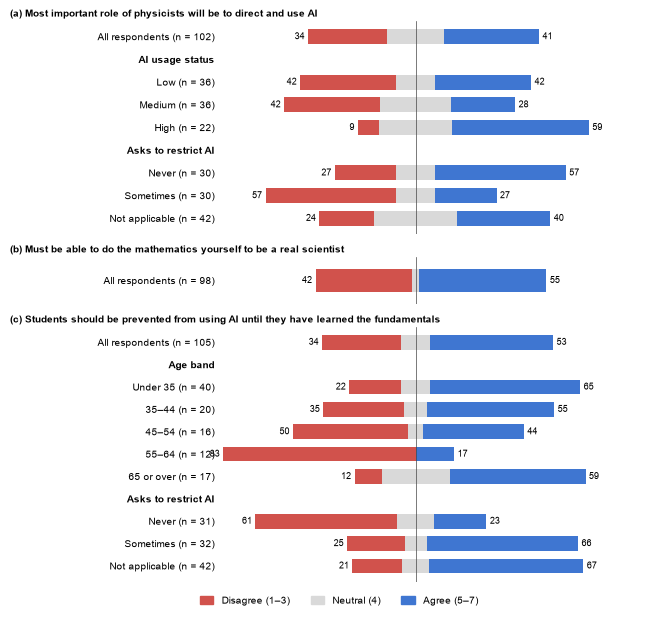

In [34]:
# Figure 3:
PANEL = {"P1_3": "(a) Most important role of physicists will be to direct and use AI", "Q80": "(b) Must be able to do the mathematics yourself to be a real scientist",
         "P3_10": "(c) Students should be prevented from using AI until they have learned the fundamentals"}
layout, fig3_rows = [], []
for c in SPLIT:
    y7 = likert(c); rows = [("bar", "All respondents", shares(y7))]
    for name in sig8.loc[sig8["Item"] == c, "Feature"]:
        x, levels = FEATURES[name]; rows.append(("head", name, None)); rows += [("bar", l, shares(y7[x == l])) for l in levels]
    layout.append((PANEL[c], rows)); fig3_rows += [{"Item": c, "Group": lab, **{k: round(v, 1) for k, v in d.items()}} for kind, lab, d in rows if kind == "bar"]
fig, axes = plt.subplots(3, 1, figsize=(W * 1.12, 185 * MM), gridspec_kw=dict(height_ratios=[len(r) + 1.3 for _, r in layout], hspace=0.13))
for ax, (title, rows) in zip(axes, layout):
    ys = np.arange(len(rows))[::-1]; ticks = []
    for y, (kind, lab, d) in zip(ys, rows):
        if kind == "head": ticks.append(lab); continue
        ticks.append(f"{lab} (n = {d['n']})")
        ax.barh(y, d["neu"], left=-d["neu"] / 2, color=GREY, height=0.66); ax.barh(y, d["dis"], left=-d["neu"] / 2 - d["dis"], color=RED, height=0.66); ax.barh(y, d["agr"], left=d["neu"] / 2, color=BLUE, height=0.66)
        ax.text(-d["neu"] / 2 - d["dis"] - 1.5, y, f"{d['dis']:.0f}", ha="right", va="center", fontsize=6.5); ax.text(d["neu"] / 2 + d["agr"] + 1.5, y, f"{d['agr']:.0f}", ha="left", va="center", fontsize=6.5)
    ax.axvline(0, color="#444444", lw=0.5); ax.set_xlim(-85, 100); ax.set_ylim(-0.7, len(rows) - 0.3); ax.set_yticks(ys); ax.set_yticklabels(ticks, fontsize=7)
    for tl, (kind, _, _) in zip(ax.get_yticklabels(), rows):
        if kind == "head": tl.set_fontweight("bold")
    ax.set_title(title, fontsize=7.5, fontweight="bold", loc="left", pad=3, x=-0.49); ax.set_xticks([]); ax.tick_params(axis="y", length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
axes[-1].legend(handles=KEY, loc="upper center", bbox_to_anchor=(0.28, -0.02), ncol=3, frameon=False, fontsize=7.5, handlelength=1.3)
fig.subplots_adjust(left=0.33); save(fig, "Figure3"); plt.show()
pd.DataFrame(fig3_rows).to_csv(OUT / "figure3_values.csv", index=False)